# Human PBMCs (10X Genomics)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2023-08-31
> - Modified: 2025-12-21

---

# Experimental Design

> - https://www.10xgenomics.com/cn/datasets/10k-human-pbmcs-3-ht-v3-1-chromium-x-3-1-high

| Sample | Cell/Tissue | Organism | Full name | Gender | Age | Disease status | Library | Source |
| - | - | - | - | - | - | - | - | - |
| Donor | PBMCs | Homo sapiens | Peripheral blood mononuclear cells | Female | 25-30 | Healthy | 10X 3' V3.1 scRNA-seq | AllCells |

> - Chromium Single Cell 3' Reagent Kits (v3.1 Chemistry Dual Index, CG000315 Rev C)
> - Chromium X
>     - input: ~ 16,000 cells
>     - recovered: 11,996 cells
> - Illumina NovaSeq 6000
> - Cell Ranger 6.1.0 with --expect-cells = 10000

---

In [1]:
import os
import numpy as np
import scanpy as sc
import pandas as pd
from matplotlib.pyplot import rc_context
import matplotlib.pyplot as plt

In [ ]:
# sc.set_figure_params(dpi=80, facecolor="white", figsize=[9, 6], fontsize=16)
# sc.set_figure_params(dpi=100, color_map="viridis_r")

# 1. Data Import

In [2]:
data_dir = os.path.expanduser(
    "~/data1/single_cell_dataset/dataset_10xGenomics/Hs_PBMCs_3Pv3_10k"
)

In [3]:
# os.makedirs(os.path.join(data_dir, "result"), exist_ok=True)
# os.makedirs(os.path.join(data_dir, "visualization"), exist_ok=True)

In [4]:
scrna = sc.read_10x_h5(
    os.path.join(
        data_dir, "matrix", "filtered_feature_bc_matrix.h5"
    )
)

/home/fugui/miniconda3/envs/r452/lib/python3.12/site-packages/anndata/_core/anndata.py:1808: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/fugui/miniconda3/envs/r452/lib/python3.12/site-packages/anndata/_core/anndata.py:1808: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [5]:
scrna.var_names_make_unique()

In [6]:
scrna

AnnData object with n_obs × n_vars = 11996 × 36601
    var: 'gene_ids', 'feature_types', 'genome'

# 2. Quality Control

In [7]:
sc.pp.filter_genes(scrna, min_cells=3)

In [8]:
scrna

AnnData object with n_obs × n_vars = 11996 × 22302
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells'

## 1). Calculate Metrics

In [9]:
# Mitochondrial genes
scrna.var["mt"] = scrna.var_names.str.startswith("MT-")

In [10]:
# Ribosomal genes
scrna.var["rp"] = scrna.var_names.str.contains("(?i)^(?:MRP|RP[LS])")

In [11]:
# Hemoglobin genes
hb = "^(HBA1|HBA2|HBAP1|HBB|HBBP1|HBD|HBE1|HBG1|HBG2|HBM|HBQ1|HBZ|HBZP1)"
scrna.var["hb"] = scrna.var_names.str.match(hb)

In [12]:
sc.pp.calculate_qc_metrics(
    scrna, qc_vars=["mt", "rp", "hb"], 
    percent_top=None, log1p=False, inplace=True
)

In [13]:
scrna.obs.head()

,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_rp,pct_counts_rp,total_counts_hb,pct_counts_hb
AAACCCAAGGCCCAAA-1,3022,12143.0,778.0,6.406984,2412.0,19.863297,0.0,0.0
AAACCCAAGTAATACG-1,2666,7810.0,493.0,6.312420,1033.0,13.226633,0.0,0.0
AAACCCAAGTCACACT-1,2934,9741.0,842.0,8.643877,1765.0,18.119289,0.0,0.0
AAACCCACAAAGCGTG-1,1525,5561.0,289.0,5.196907,2551.0,45.873043,0.0,0.0
AAACCCACAATCGAAA-1,2077,7398.0,656.0,8.867262,2629.0,35.536633,0.0,0.0


## 2). Visualizate Metrics

In [14]:
def run_scanpy_pipeline(adata, n_top_genes=2000, ndim=10, resolution=0.5):
    sc.pp.normalize_total(adata)
    sc.pp.log1p(adata)
    sc.pp.highly_variable_genes(adata, n_top_genes=n_top_genes)
    sc.tl.pca(adata, n_comps=ndim)
    sc.pp.neighbors(adata, n_pcs=ndim)
    sc.tl.umap(adata)
    sc.tl.tsne(adata)
    sc.tl.leiden(
        adata, resolution=resolution, key_added="clusters", 
        flavor="igraph")
    return adata

In [15]:
scrna_temp = run_scanpy_pipeline(scrna.copy(), ndim=20)
scrna_temp

AnnData object with n_obs × n_vars = 11996 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'clusters'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'tsne', 'clusters'
    obsm: 'X_pca', 'X_umap', 'X_tsne'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

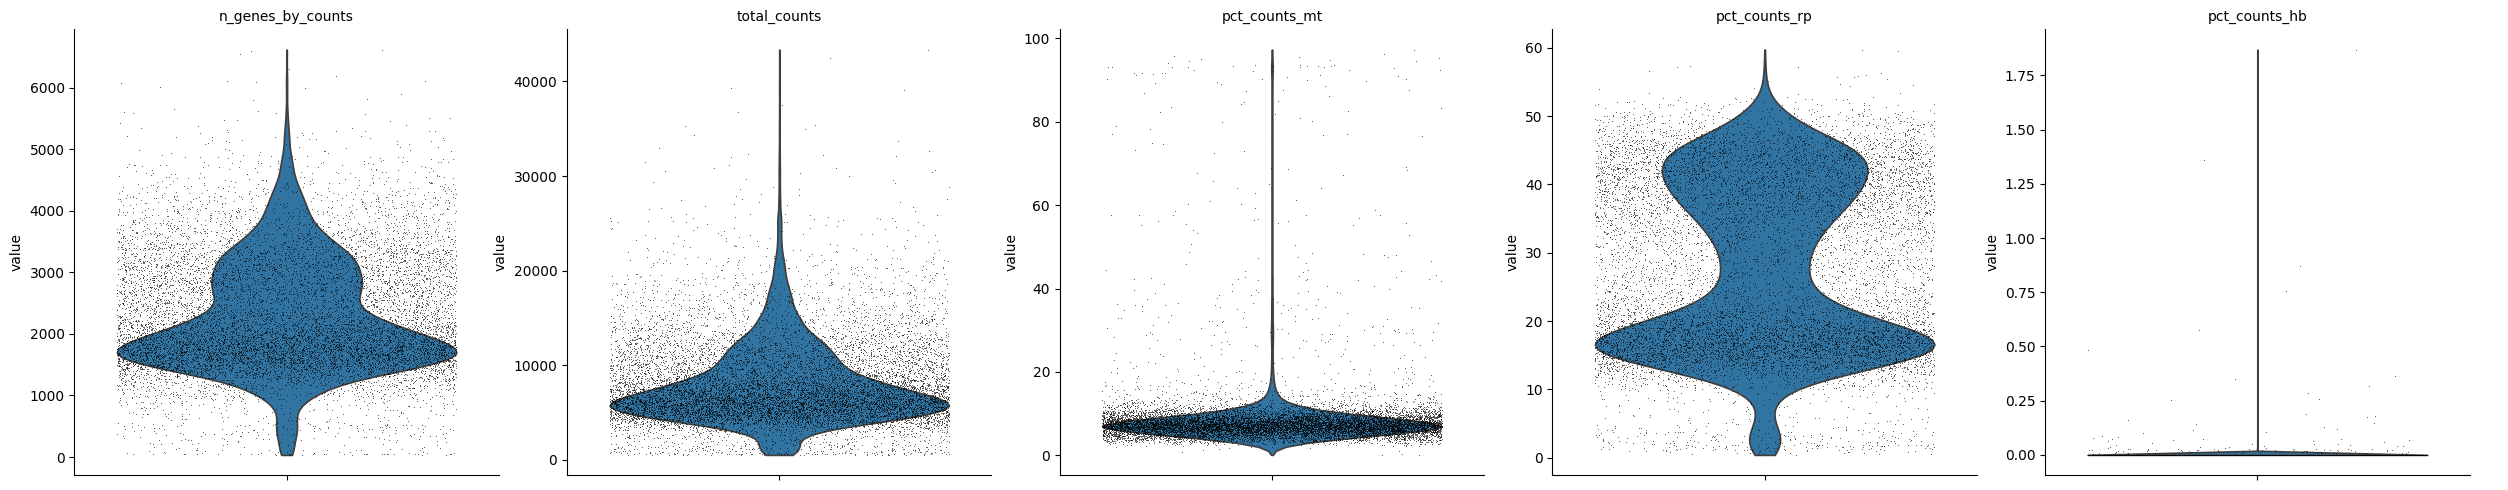

In [16]:
sc.pl.violin(
    scrna_temp, [
        "n_genes_by_counts", "total_counts", "pct_counts_mt", 
        "pct_counts_rp", "pct_counts_hb"
    ],
    jitter=0.4, size=0.5, multi_panel=True
)

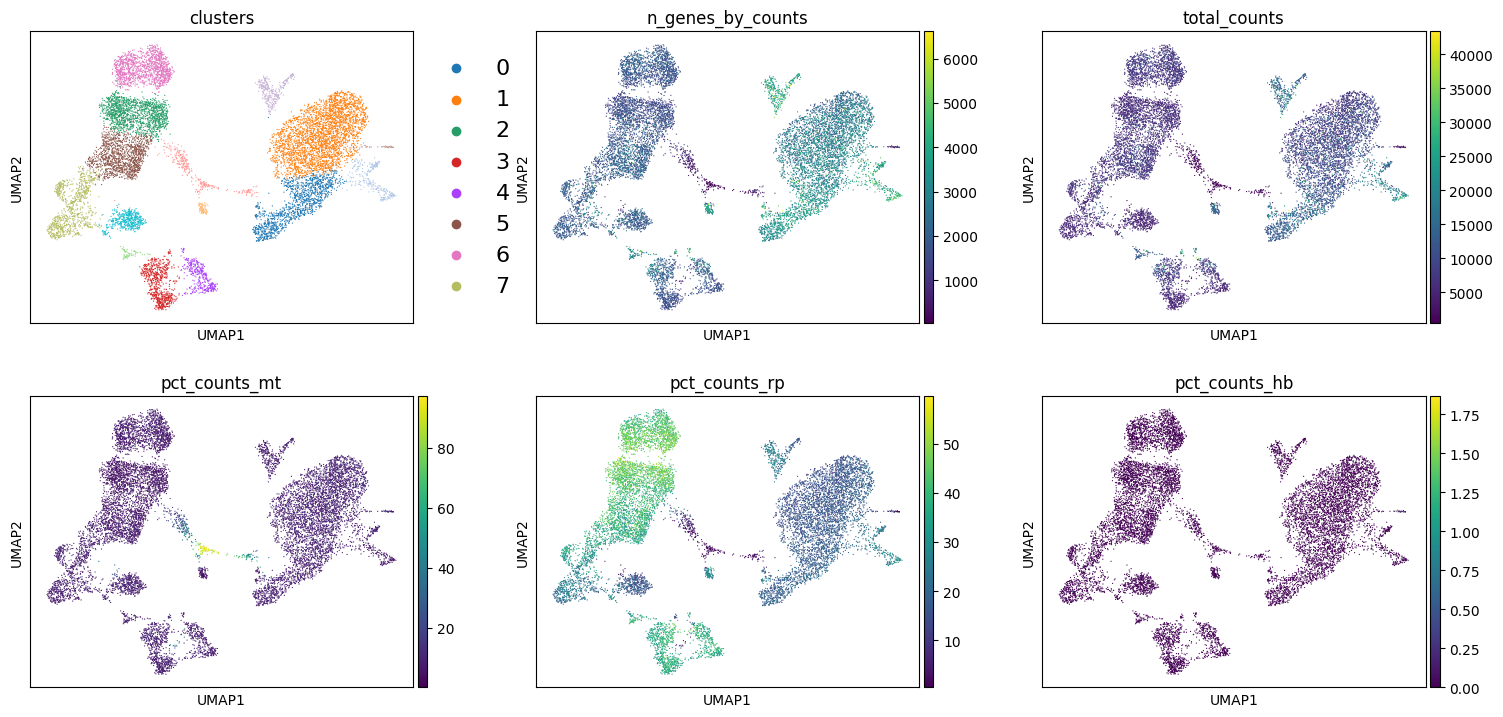

In [17]:
with rc_context({"figure.figsize": (5, 4)}):
    sc.pl.umap(
        scrna_temp, color=[
            "clusters", "n_genes_by_counts", "total_counts",
            "pct_counts_mt", "pct_counts_rp", "pct_counts_hb"
        ],
        wspace=0.2, size=3, ncols=3, legend_fontsize = 16
    )

## 3). Filtering Empty Droplets

In [18]:
sc.pp.filter_cells(scrna, min_genes=200)
scrna = scrna[scrna.obs.pct_counts_mt < 25]
scrna

View of AnnData object with n_obs × n_vars = 11734 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'

/home/fugui/miniconda3/envs/r452/lib/python3.12/site-packages/anndata/_core/anndata.py:1190: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  df[key] = c
/home/fugui/miniconda3/envs/r452/lib/python3.12/site-packages/anndata/_core/anndata.py:1190: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  df[key] = c


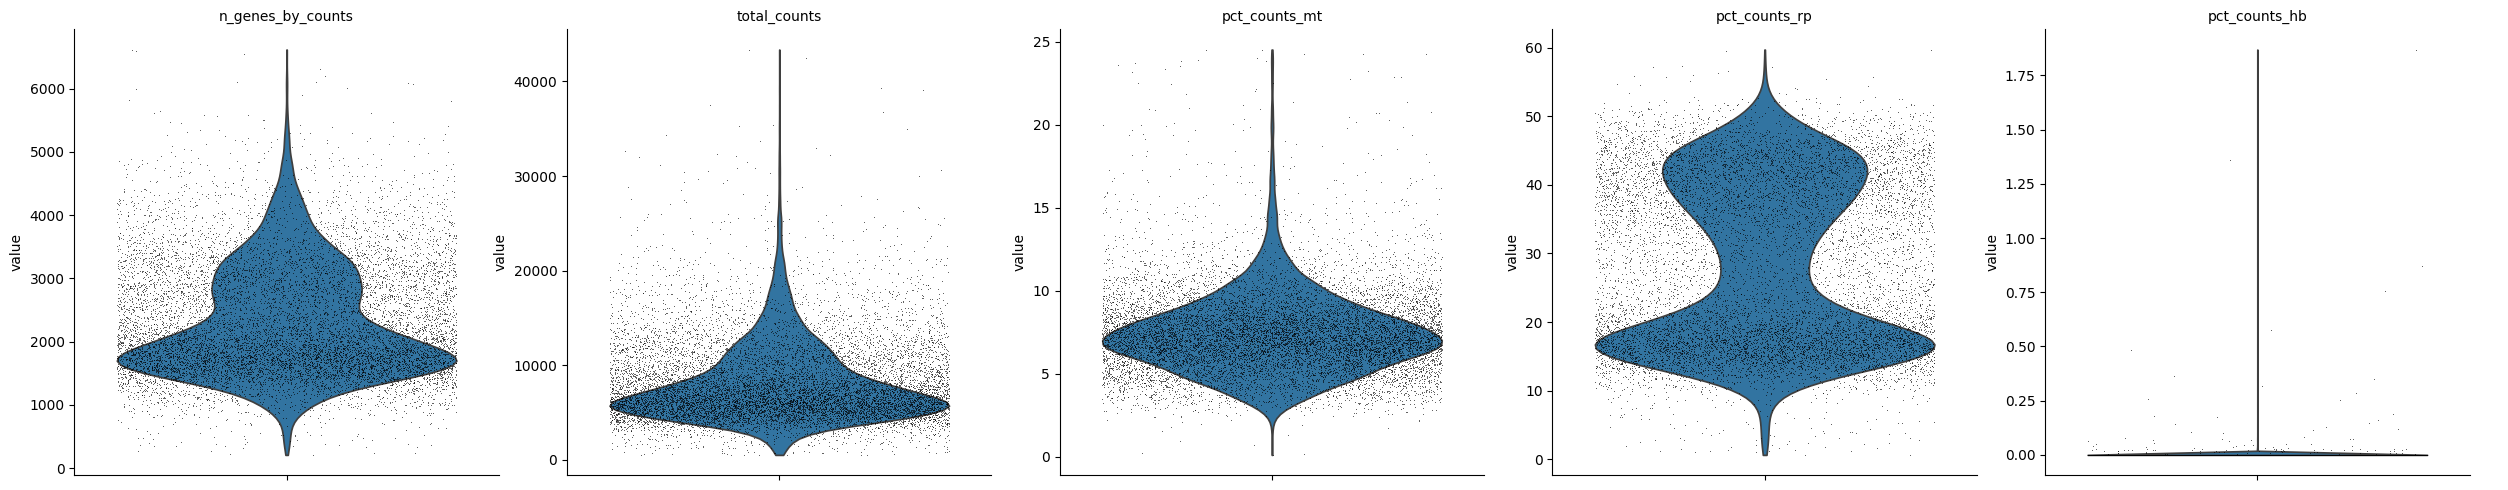

In [19]:
with rc_context({"figure.figsize": (7, 6)}):
    sc.pl.violin(
        scrna, [
            "n_genes_by_counts", "total_counts", "pct_counts_mt", 
            "pct_counts_rp", "pct_counts_hb"
        ],
        jitter=0.4, size=0.5, multi_panel=True
    )

## 4). Doublet Detection

### a). [Scrublet](https://github.com/swolock/scrublet)

In [20]:
sc.pp.scrublet(scrna)

In [21]:
scrna.obs["predicted_doublet"].value_counts()

predicted_doublet
False    11185
True       549
Name: count, dtype: int64

### b). [DoubletDetection](https://github.com/JonathanShor/DoubletDetection)

In [22]:
import doubletdetection

In [23]:
clf = doubletdetection.BoostClassifier()

In [24]:
labels = clf.fit(scrna.X).predict()

  0%|          | 0/10 [00:00<?, ?it/s]

In [25]:
scores = clf.doublet_score()

In [26]:
scrna.obs["doubletdetection_score"] = scores
scrna.obs["doubletdetection_class"] = labels.astype(bool)

In [27]:
scrna.obs["doubletdetection_class"].value_counts()

doubletdetection_class
False    10835
True       899
Name: count, dtype: int64

### c). [scDblFinder](https://github.com/plger/scDblFinder)

In [28]:
# data_mat = scrna.X.T

In [29]:
# os.environ["R_HOME"] = os.path.expanduser("~/miniconda3/envs/r452/lib/R")
# import logging
# import anndata2ri
# import rpy2.rinterface_lib.callbacks as rcb
# import rpy2.robjects as ro

# rcb.logger.setLevel(logging.ERROR)
# ro.pandas2ri.activate()
# anndata2ri.activate()

# %load_ext rpy2.ipython

In [30]:
# %%R
# library(Seurat)
# # suppressPackageStartupMessages(library(scDblFinder))
# library(scDblFinder)

In [31]:
# %%R -i data_mat -o doublet_score -o doublet_class

# set.seed(123)
# sce <- SingleCellExperiment(list(counts = data_mat)) |>
#     scDblFinder(verbose = FALSE)
# doublet_score = sce$scDblFinder.score
# doublet_class = sce$scDblFinder.class

In [32]:
# adata.obs["scDblFinder_score"] = doublet_score
# adata.obs["scDblFinder_class"] = doublet_class

In [33]:
# adata.obs.scDblFinder_class.value_counts()

### Flitering

In [34]:
scrna_temp = run_scanpy_pipeline(scrna.copy(), ndim=20)

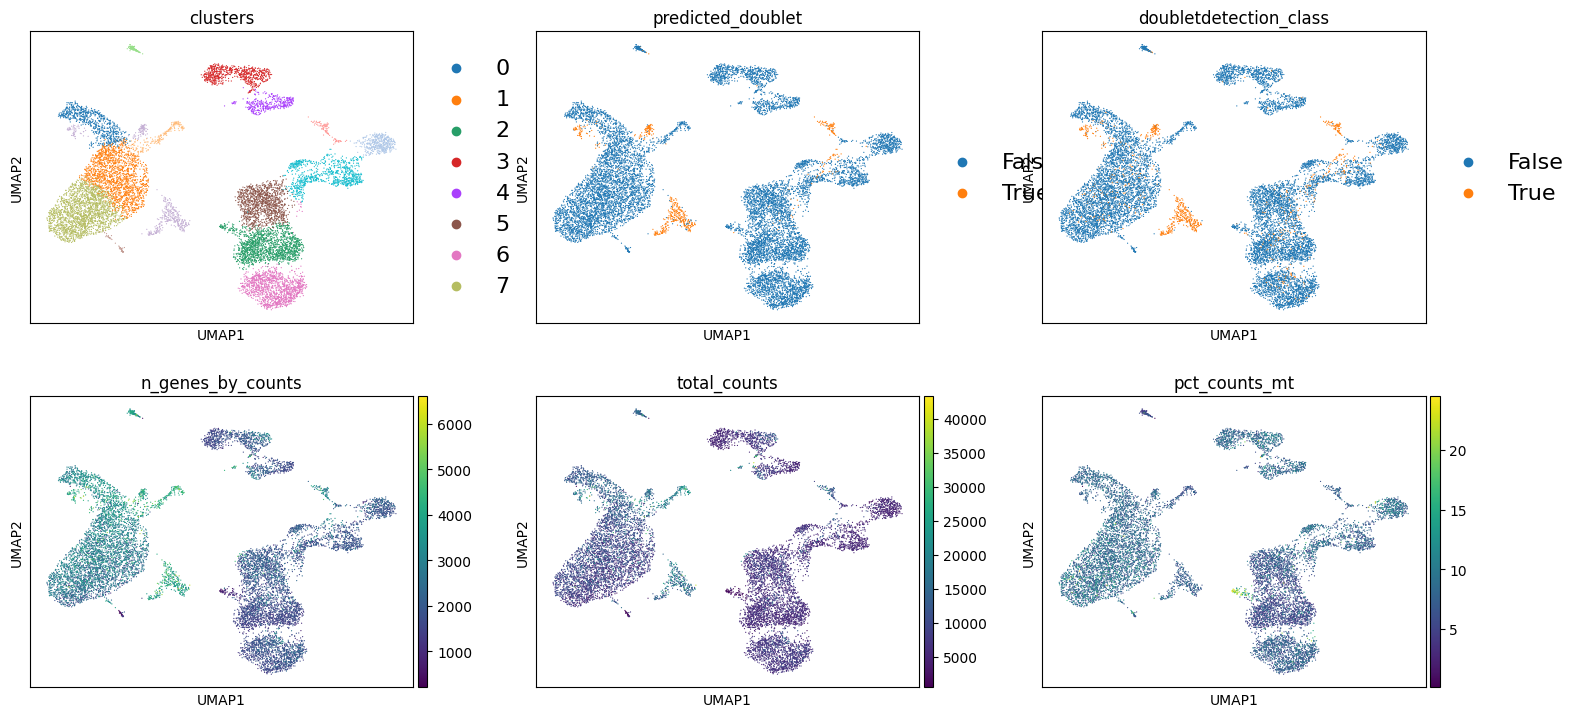

In [35]:
with rc_context({"figure.figsize": (5, 4)}):
    sc.pl.umap(
        scrna_temp, color=[
            "clusters", "predicted_doublet", "doubletdetection_class",
            "n_genes_by_counts", "total_counts", "pct_counts_mt"
        ],
        wspace=0.2, size=3, ncols=3, legend_fontsize = 16
    )

In [36]:
scrna = scrna[~scrna.obs["doubletdetection_class"]].copy()
scrna

AnnData object with n_obs × n_vars = 10835 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'scrublet'

## 5). Visualizate Metrics

In [37]:
scrna_temp = run_scanpy_pipeline(scrna.copy(), ndim=20)

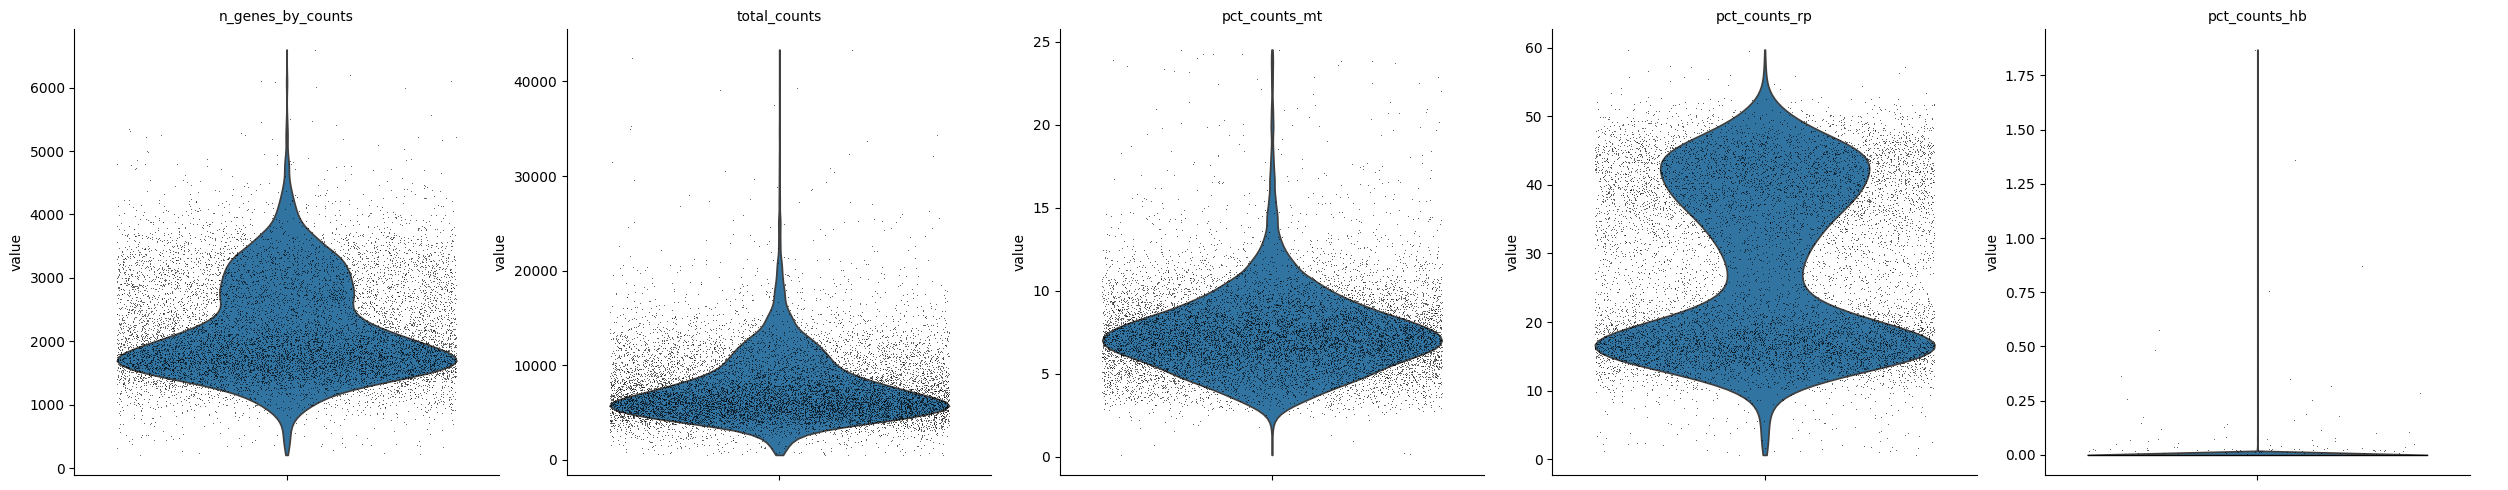

In [38]:
sc.pl.violin(
    scrna_temp, [
        "n_genes_by_counts", "total_counts", "pct_counts_mt", 
        "pct_counts_rp", "pct_counts_hb"
    ],
    jitter=0.4, size=0.5, multi_panel=True
)

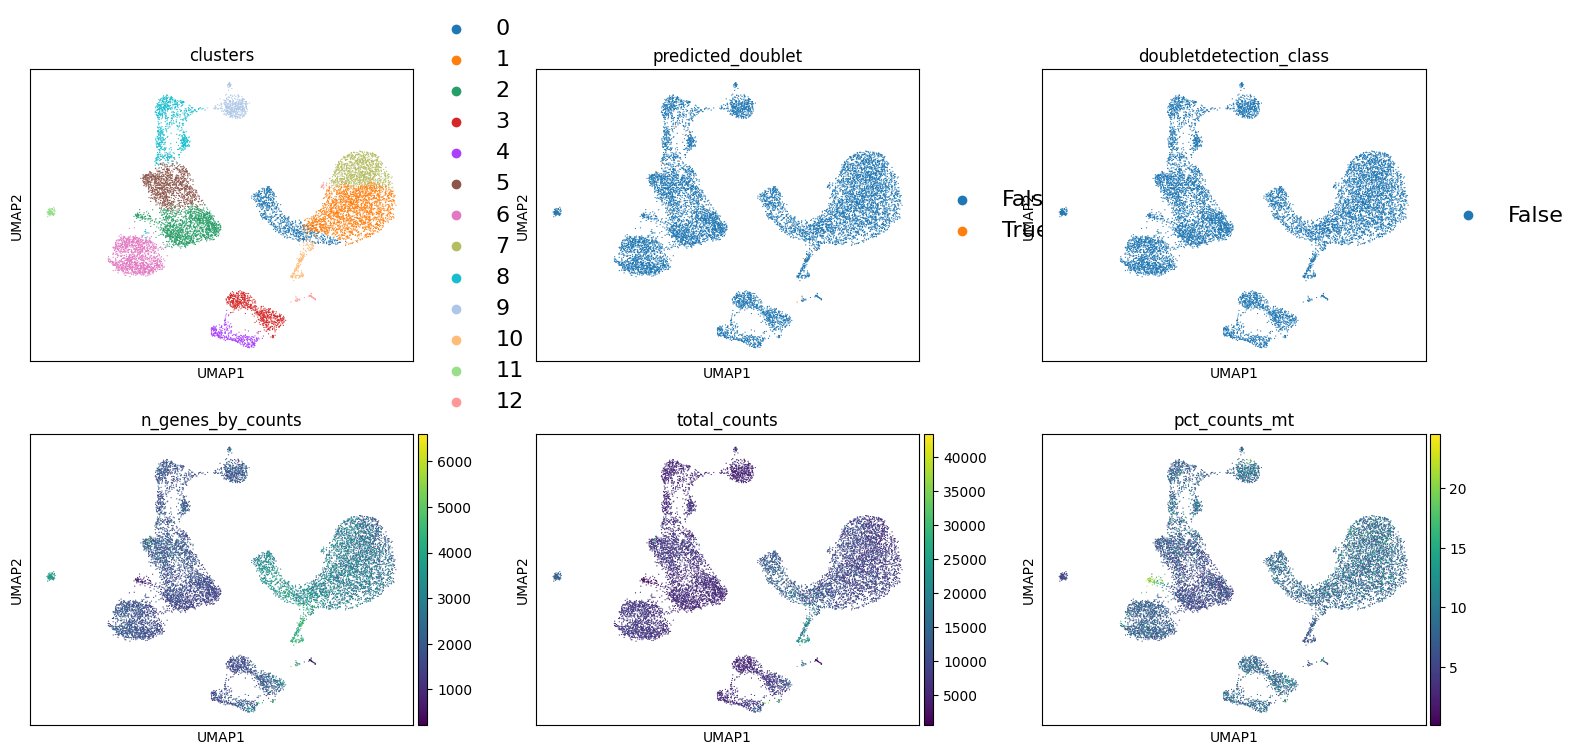

In [39]:
with rc_context({"figure.figsize": (5, 4)}):
    sc.pl.umap(
        scrna_temp, color=[
            "clusters", "predicted_doublet", "doubletdetection_class",
            "n_genes_by_counts", "total_counts", "pct_counts_mt"
        ],
        wspace=0.2, size=3, ncols=3, legend_fontsize = 16
    )

In [40]:
scrna_temp.obs[["n_genes_by_counts", "total_counts", "pct_counts_mt"]].describe()

,n_genes_by_counts,total_counts,pct_counts_mt
count,10835.000000,10835.000000,10835.000000
mean,2196.332257,7569.035156,7.452349
std,785.828138,3654.089600,2.546482
min,210.000000,514.000000,0.112867
25%,1620.000000,5176.000000,5.828641
50%,1997.000000,6698.000000,7.180851
75%,2738.000000,9163.000000,8.648418
max,6600.000000,43373.000000,24.534502


In [41]:
# def is_outlier(adata, metric: str, nmads: int):
#     M = adata.obs[metric]
#     outlier = (M < np.median(M) - nmads * median_abs_deviation(M)) | (
#         np.median(M) + nmads * median_abs_deviation(M) < M
#     )
#     return outlier

In [42]:
# adata.obs["outlier"] = (
#     is_outlier(adata, "log1p_total_counts", 5)
#     | is_outlier(adata, "log1p_n_genes_by_counts", 5)
#     | is_outlier(adata, "pct_counts_in_top_20_genes", 5)
# )
# adata.obs.outlier.value_counts()

## 6). Filtering Low-quality Cells

In [43]:
sc.pp.filter_cells(scrna, min_genes=500)
sc.pp.filter_cells(scrna, max_counts=25000)
scrna = scrna[scrna.obs.pct_counts_mt < 15]
scrna = scrna[scrna.obs.pct_counts_hb < 1]

In [44]:
scrna

View of AnnData object with n_obs × n_vars = 10614 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'scrublet'

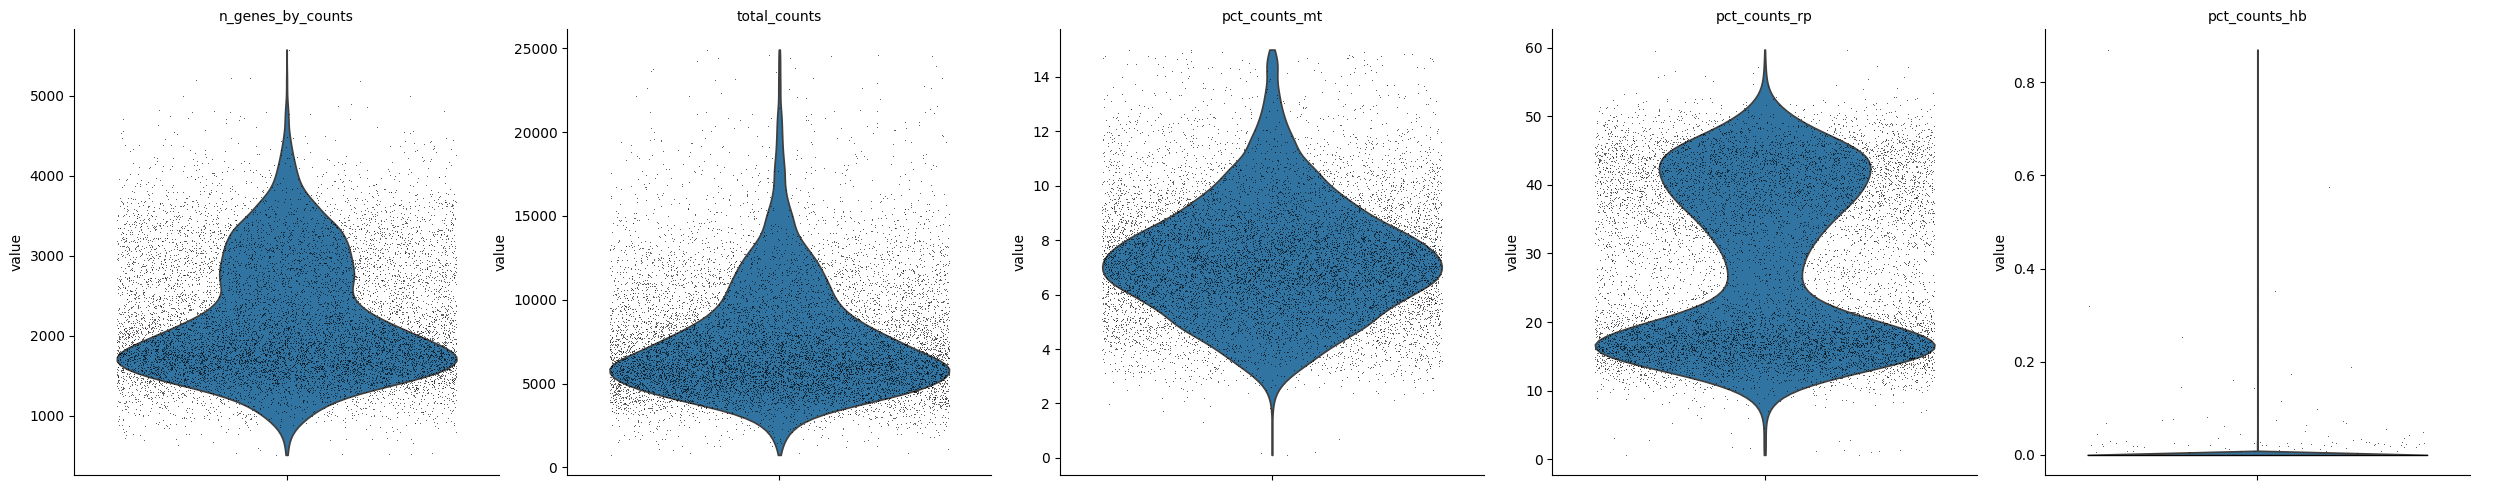

In [93]:
with rc_context({"figure.figsize": (3, 3)}):
    sc.pl.violin(
        scrna, [
            "n_genes_by_counts", "total_counts", "pct_counts_mt", 
            "pct_counts_rp", "pct_counts_hb"
        ],
        jitter=0.4, size=0.5, multi_panel=True
    )

## 7). Evaluating Noise

## 8). Visualization

# 3. Normalization

In [46]:
scrna

View of AnnData object with n_obs × n_vars = 10614 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'scrublet'

In [47]:
scrna.layers["counts"] = scrna.X.copy()
scrna

/tmp/ipykernel_33131/3213987602.py:1: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.
  scrna.layers["counts"] = scrna.X.copy()


AnnData object with n_obs × n_vars = 10614 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'scrublet'
    layers: 'counts'

In [48]:
# Logarithmize the data
sc.pp.normalize_total(scrna, target_sum=1e4)
scrna

AnnData object with n_obs × n_vars = 10614 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'scrublet'
    layers: 'counts'

In [49]:
sc.pp.log1p(scrna)
scrna

AnnData object with n_obs × n_vars = 10614 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'scrublet', 'log1p'
    layers: 'counts'

In [50]:
# Feature selection
sc.pp.highly_variable_genes(scrna, n_top_genes=3000)
scrna

AnnData object with n_obs × n_vars = 10614 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'scrublet', 'log1p', 'hvg'
    layers: 'counts'

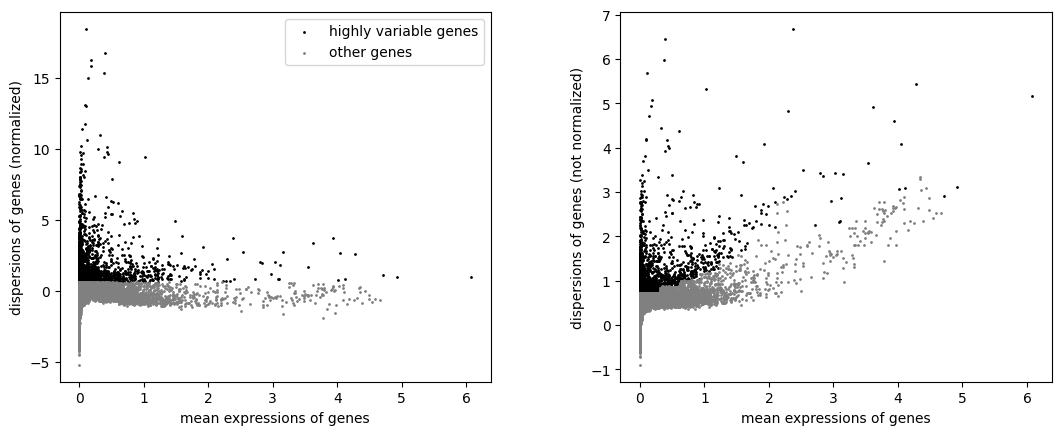

In [51]:
sc.pl.highly_variable_genes(scrna)

In [52]:
scrna.layers["scaled"] = np.ascontiguousarray(scrna.X.toarray())
sc.pp.regress_out(scrna, ["pct_counts_mt"], layer="scaled")
sc.pp.scale(scrna, max_value=10, layer="scaled")
scrna

AnnData object with n_obs × n_vars = 10614 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'scrublet', 'log1p', 'hvg'
    layers: 'counts', 'scaled'

# 4. Linear Dimensionality Reduction

In [53]:
sc.pp.pca(scrna, n_comps=50, layer="scaled", svd_solver="arpack")
scrna

AnnData object with n_obs × n_vars = 10614 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'scrublet', 'log1p', 'hvg', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts', 'scaled'

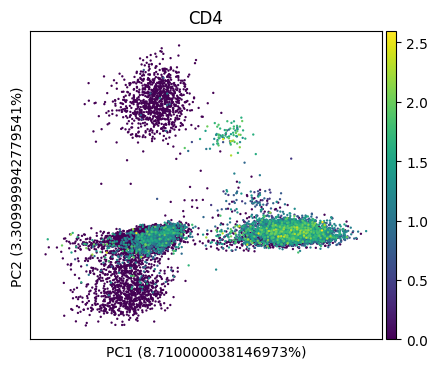

In [66]:
with rc_context({"figure.figsize": (5, 4)}):
    sc.pl.pca(scrna, annotate_var_explained=True, color="CD4")

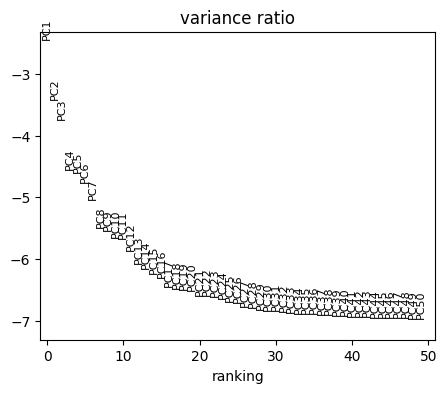

In [65]:
with rc_context({"figure.figsize": (5, 4)}):
    sc.pl.pca_variance_ratio(scrna, n_pcs=50, log=True)

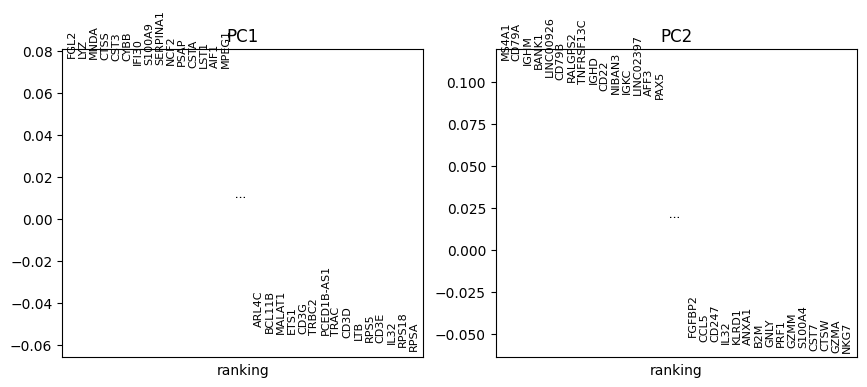

In [64]:
with rc_context({"figure.figsize": (5, 4)}):
    sc.pl.pca_loadings(scrna, components=(1, 2), include_lowest=True)

In [57]:
nPCs = 30

# 5. Integration (Skip)

# 6. Computing The Neighborhood Graph

In [58]:
sc.pp.neighbors(scrna, n_neighbors=20, n_pcs=nPCs)
scrna

AnnData object with n_obs × n_vars = 10614 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: 'counts', 'scaled'
    obsp: 'distances', 'connectivities'

# 7. Non-linear Dimensionality Reduction

In [59]:
sc.tl.umap(scrna, min_dist=0.5)
scrna

AnnData object with n_obs × n_vars = 10614 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'scaled'
    obsp: 'distances', 'connectivities'

In [60]:
sc.tl.tsne(scrna, n_pcs=nPCs, perplexity=30, use_rep="X_pca")
scrna

AnnData object with n_obs × n_vars = 10614 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'tsne'
    obsm: 'X_pca', 'X_umap', 'X_tsne'
    varm: 'PCs'
    layers: 'counts', 'scaled'
    obsp: 'distances', 'connectivities'

In [61]:
# fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 4), gridspec_kw={"wspace": 0.9})

# ax1_dict = sc.pl.dotplot(pbmc, marker_genes_dict, groupby="bulk_labels", ax=ax1, show=False)
# ax2_dict = sc.pl.stacked_violin(pbmc, marker_genes_dict, groupby="bulk_labels", ax=ax2, show=False)
# ax3_dict = sc.pl.matrixplot(pbmc, marker_genes_dict, groupby="bulk_labels", ax=ax3, show=False, cmap="viridis")

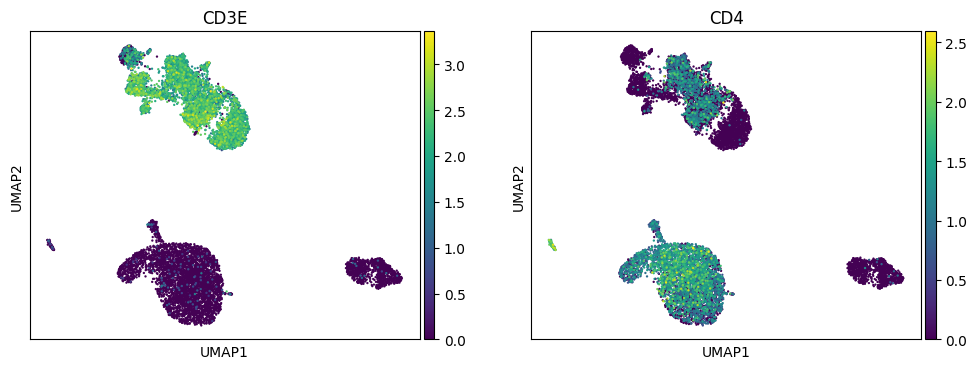

In [62]:
with rc_context({"figure.figsize": (5, 4)}):
    sc.pl.umap(scrna, color=["CD3E", "CD4"])

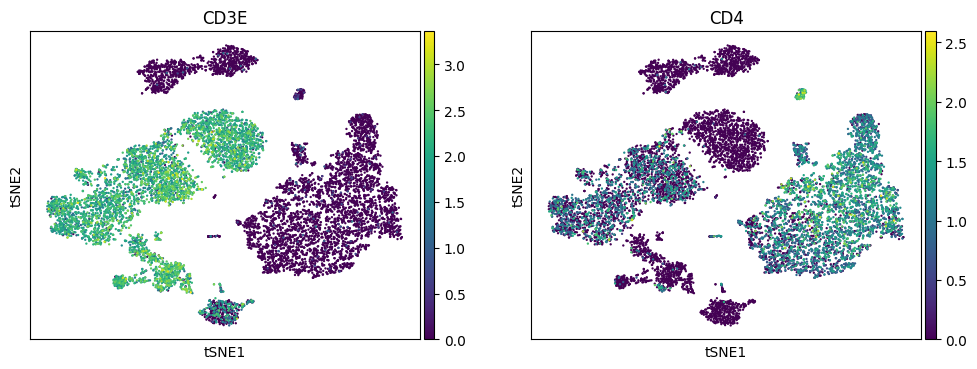

In [63]:
with rc_context({"figure.figsize": (5, 4)}):
    sc.pl.tsne(scrna, color=["CD3E", "CD4"])

# 8. Clustering

In [67]:
# Using the igraph implementation and a fixed number of iterations can be significantly faster, especially for larger datasets
sc.tl.leiden(
    scrna, flavor="igraph", n_iterations=2, resolution=0.7, 
    directed=False, random_state=0)
scrna

AnnData object with n_obs × n_vars = 10614 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class', 'n_counts', 'leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'tsne', 'leiden'
    obsm: 'X_pca', 'X_umap', 'X_tsne'
    varm: 'PCs'
    layers: 'counts', 'scaled'
    obsp: 'distances', 'connectivities'

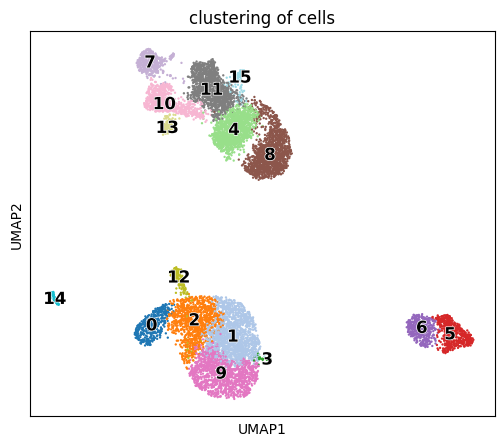

In [68]:
with rc_context({"figure.figsize": (6, 5)}):
    sc.pl.umap(
        scrna, color=["leiden"], 
        legend_loc="on data", legend_fontsize=12, legend_fontoutline=1,
        add_outline=False,
        title="clustering of cells", palette="tab20"
    )

# 9. Cluster Biomarkers

## Marker Identification

In [103]:
sc.tl.rank_genes_groups(
    scrna, "leiden", mask_var="highly_variable", method="wilcoxon", 
    n_genes=scrna.shape[1]
)

In [104]:
scrna

AnnData object with n_obs × n_vars = 10614 × 22302
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rp', 'pct_counts_rp', 'total_counts_hb', 'pct_counts_hb', 'n_genes', 'doublet_score', 'predicted_doublet', 'doubletdetection_score', 'doubletdetection_class', 'n_counts', 'leiden', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells', 'mt', 'rp', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'scrublet', 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'tsne', 'leiden', 'leiden_colors', 'rank_genes_groups', 'cell_type_colors', 'dendrogram_leiden'
    obsm: 'X_pca', 'X_umap', 'X_tsne'
    varm: 'PCs'
    layers: 'counts', 'scaled'
    obsp: 'distances', 'connectivities'

In [105]:
sc.get.rank_genes_groups_df(scrna, group='0').head()

,names,scores,logfoldchanges,pvals,pvals_adj
0,LST1,33.318962,4.267178,2.051837e-243,6.155512e-240
1,FCGR3A,33.113010,6.121806,1.931029e-240,2.896544e-237
2,CDKN1C,32.185020,8.575219,2.859748e-227,2.859748e-224
3,AIF1,31.985973,3.946404,1.708690e-224,1.281518e-221
4,MS4A7,31.705750,4.699254,1.294550e-220,7.767297e-218


In [106]:
pd.DataFrame(scrna.uns["rank_genes_groups"]["names"]).head(10)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
0,LST1,CTSS,AIF1,PPBP,BCL11B,MS4A1,IGHD,GNLY,CD8B,S100A8,CCL5,IL32,CST3,KLRB1,LILRA4,IL32
1,FCGR3A,LYZ,CPVL,NRGN,TCF7,CD79A,IGHM,PRF1,RPS5,S100A9,IL32,LTB,HLA-DPB1,GZMK,ITM2C,RTKN2
2,CDKN1C,FGL2,HLA-DPA1,PF4,CCR7,BANK1,CD79A,NKG7,CD8A,S100A12,NKG7,IL7R,CLEC10A,KLRG1,PLD4,IL2RA
3,AIF1,MNDA,CALHM6,CAVIN2,RPS5,CD79B,TCL1A,KLRD1,CCR7,VCAN,GZMA,CD2,HLA-DQA1,NKG7,UGCG,ARL4C
4,MS4A7,CD14,SERPINA1,GP1BB,CD3E,RALGPS2,CD74,CTSW,RPS18,MNDA,CST7,TRAC,HLA-DRB1,GZMA,IRF8,LTB
5,IFITM3,VCAN,NPC2,TUBB1,TRAC,CD74,MS4A1,CST7,KLRK1,LYZ,B2M,ITGB1,HLA-DPA1,CCL5,CCDC50,TRAC
6,FCER1G,NEAT1,MARCKS,RGS18,IL7R,HLA-DQA1,CD79B,GZMA,TCF7,FOS,CTSW,CD3D,HLA-DRA,CTSW,PPP1R14B,ISG20
7,SMIM25,S100A9,CST3,HIST1H2AC,RPSA,TNFRSF13C,HLA-DRA,KLRF1,LEF1,CTSD,CD3D,CD3E,CD74,NCR3,SERPINF1,CD3D
8,COTL1,CYBB,FTH1,SPARC,CD3G,HLA-DRA,LINC00926,HOPX,NOSIP,AC020656.1,GZMM,CD3G,HLA-DRB5,IL32,TCF4,SYNE2
9,HES4,FOS,WARS,GNG11,RPS18,LINC00926,FCER2,CD247,BCL11B,APLP2,KLRG1,LIME1,HLA-DQB1,CST7,IRF7,FOXP3


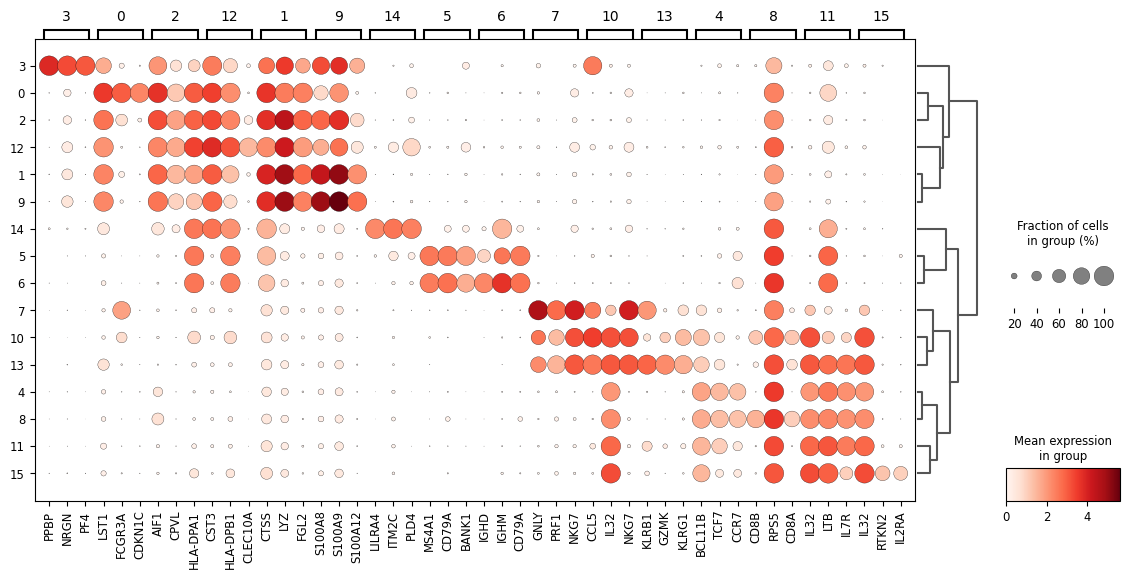

In [108]:
sc.pl.rank_genes_groups_dotplot(
    scrna, n_genes=3, 
    # values_to_plot="logfoldchanges", min_logfoldchange=3, 
    figsize=[14, 6])

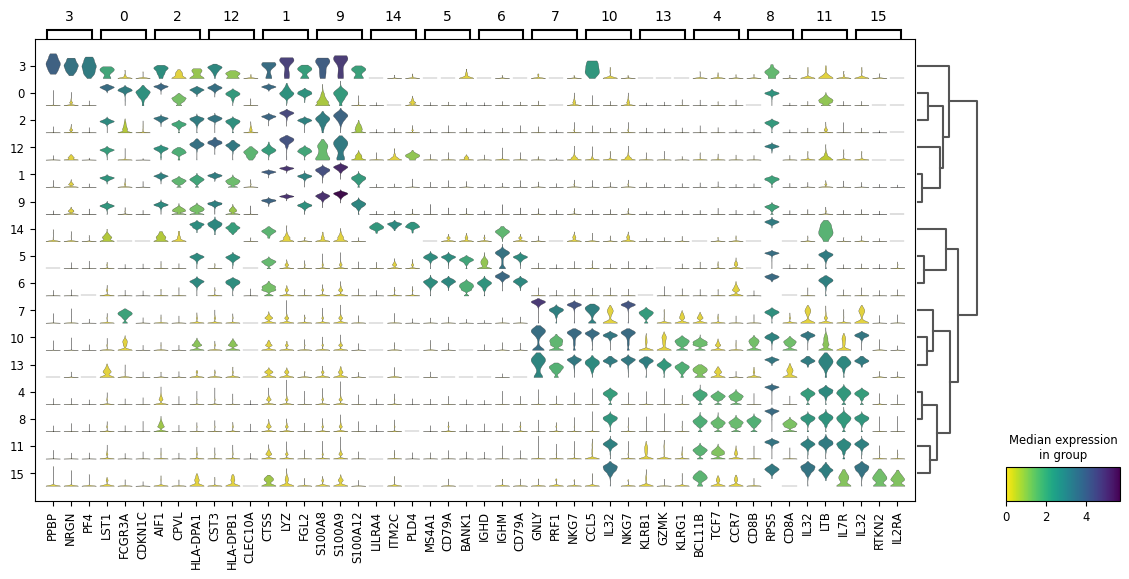

In [110]:
sc.pl.rank_genes_groups_stacked_violin(
    scrna, n_genes=3, cmap="viridis_r", figsize=[14, 6]
)

{'heatmap_ax': <Axes: >,
 'groupby_ax': <Axes: xlabel='leiden'>,
 'dendrogram_ax': <Axes: >,
 'gene_groups_ax': <Axes: >}

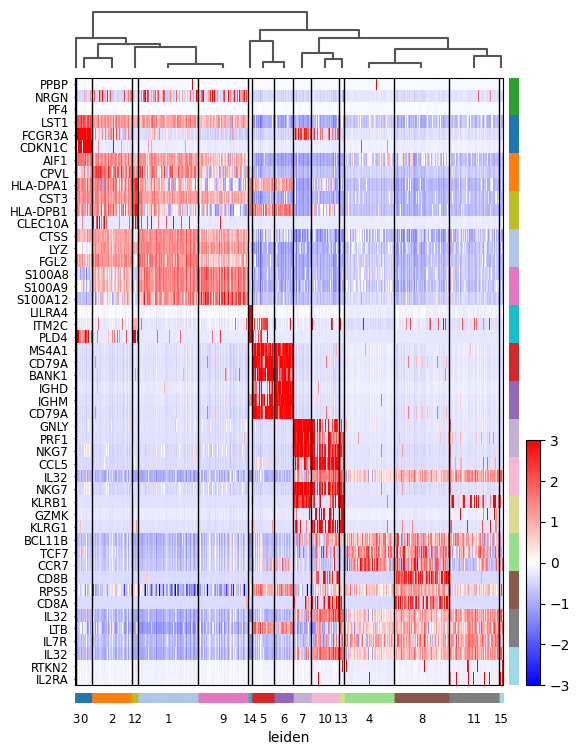

In [113]:
sc.pl.rank_genes_groups_heatmap(
    scrna, n_genes=3, use_raw=False, swap_axes=True,
    vmin=-3, vmax=3, cmap="bwr", layer="scaled",
    figsize=(6, 9), show=False
)

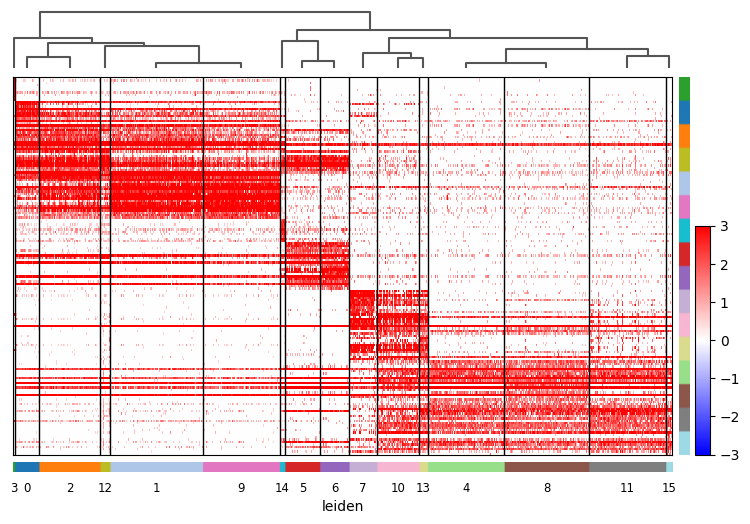

In [114]:
sc.pl.rank_genes_groups_heatmap(
    scrna, n_genes=10, use_raw=False, swap_axes=True,
    show_gene_labels=False, vmin=-3, vmax=3,
    cmap="bwr", figsize=(9, 6)
)

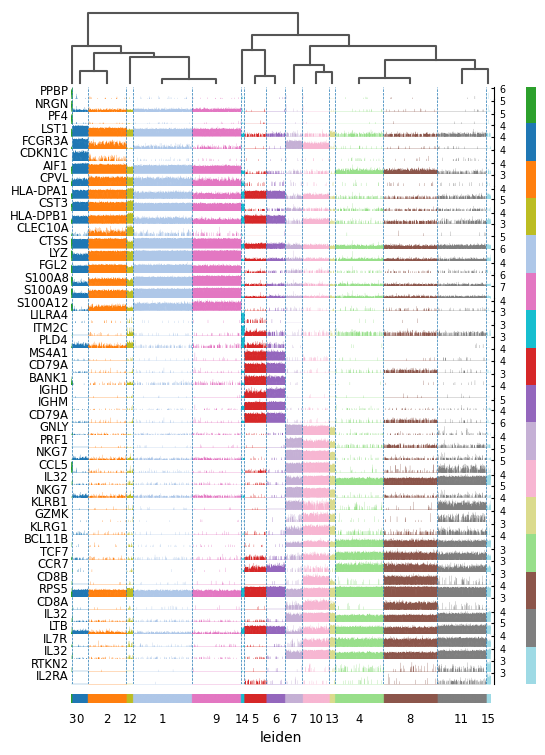

In [116]:
sc.pl.rank_genes_groups_tracksplot(scrna, n_genes=3, figsize=(6, 9))

# 10. Cell-type Annotation

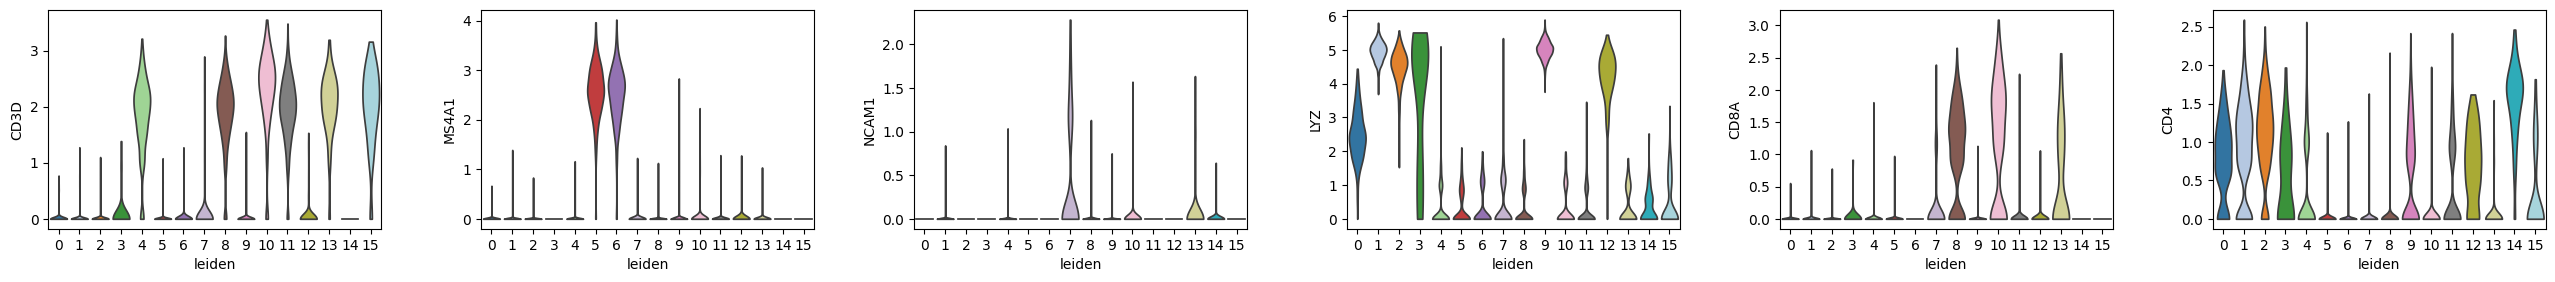

In [88]:
geneset = ["CD3D", "MS4A1", "NCAM1", "LYZ", "CD8A", "CD4"]
with rc_context({"figure.figsize": (4.5, 3)}):
    sc.pl.violin(scrna, geneset, groupby="leiden", stripplot=False)

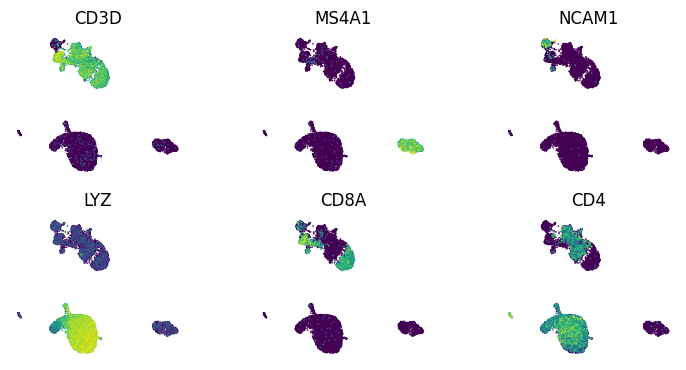

In [74]:
with rc_context({"figure.figsize": (2, 2)}):
    sc.pl.umap(
        scrna, color=geneset, size=5, ncols=3, 
        frameon=False, colorbar_loc=None
    )

In [75]:
marker_genes = {
    "B Cells": ["CD79A", "MS4A1"],
    "Plasma": ["JCHAIN"],
    "T Cells": ["CD3D", "CD3E", "CD3G", "CD4", "CD8A", "CD8B"],
    "NK Cells": ["GNLY", "NKG7"],
    "Myeloid": ["CST3", "LYZ"],
    "Monocytes": ["CD14", "FCGR3A"],
    "Dendritic": ["FCER1A", "CD1C"]
}

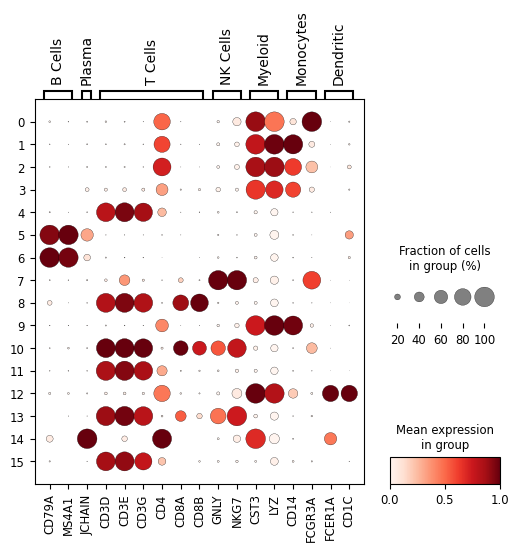

In [76]:
sc.pl.dotplot(
    scrna, marker_genes, groupby="leiden", standard_scale="var", figsize=[6, 5]
)

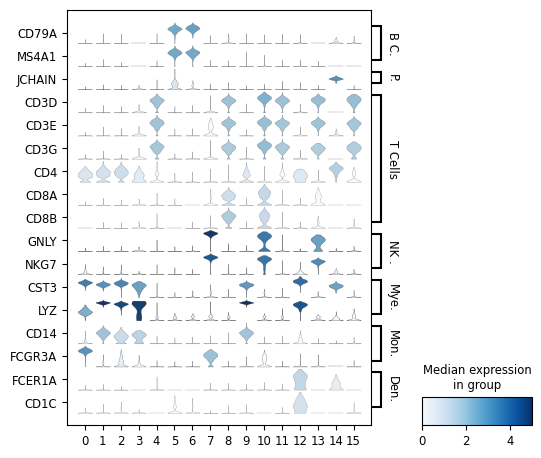

In [77]:
sc.pl.stacked_violin(
    scrna, marker_genes, groupby="leiden", swap_axes=True, figsize=[6, 5])

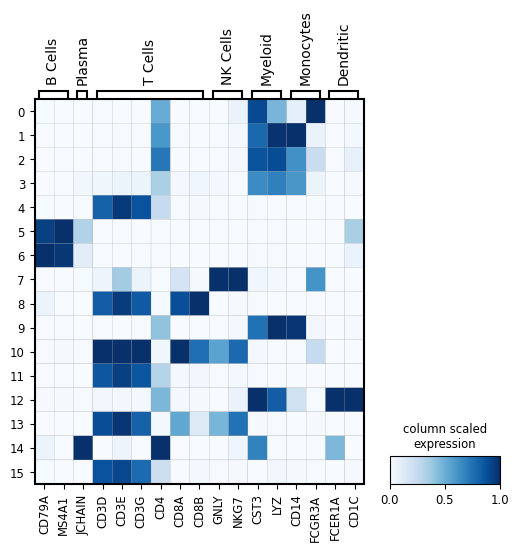

In [78]:
sc.pl.matrixplot(
    scrna, marker_genes, groupby="leiden", standard_scale="var", 
    cmap="Blues", dendrogram=False, figsize=[6, 5],
    colorbar_title="column scaled\nexpression",
)

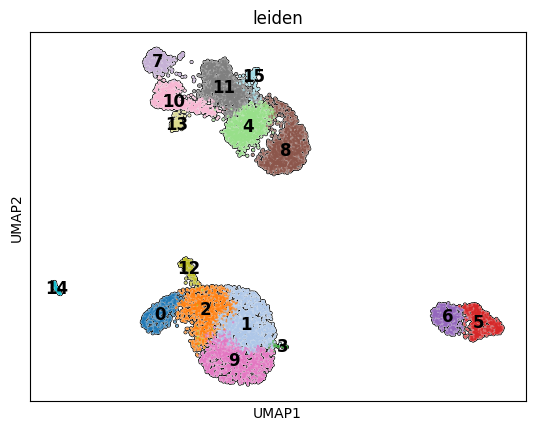

In [79]:
sc.pl.umap(
    scrna, color=["leiden"], 
    legend_loc="on data", legend_fontsize=12,
    add_outline=True)

In [84]:
cluster2annotation = {
    "0": "Non-classical Monocytes", "1": "Intermediate Monocytes", "2": "Classical Monocytes",
    "3": "Platelets", "4": "Naïve/Memory CD4 T", "5": "Activated CD4 T",
    "6": "Naive B", "7": "Plasma Cells", "8": "Naïve/Memory CD8 T",
    "9": "Cytotoxic CD8 T", "10": "Cytotoxic CD8 T", "11": "NK Cells",
    "12": "Dendritic Cells (cDC2)", "13": "pDC", "14": "Cytotoxic CD8 T",
    "15": "Treg"
}

In [85]:
scrna.obs["cell_type"] = scrna.obs["leiden"].map(cluster2annotation).astype("category")

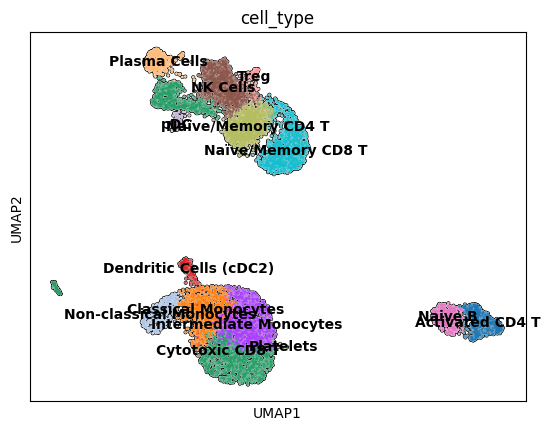

In [86]:
sc.pl.umap(
    scrna, color=["cell_type"], 
    legend_loc="on data", legend_fontsize=10, 
    add_outline=True)

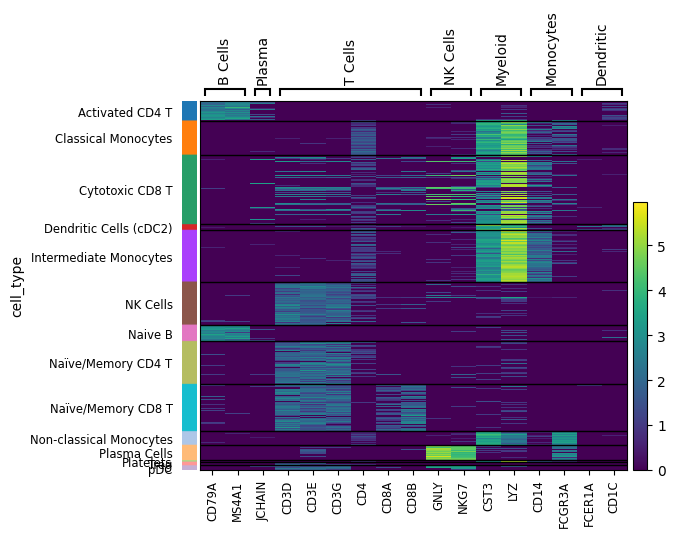

In [82]:
sc.pl.heatmap(
    scrna, marker_genes, groupby="cell_type", cmap="viridis",
    dendrogram=False, figsize=[6, 5]
)

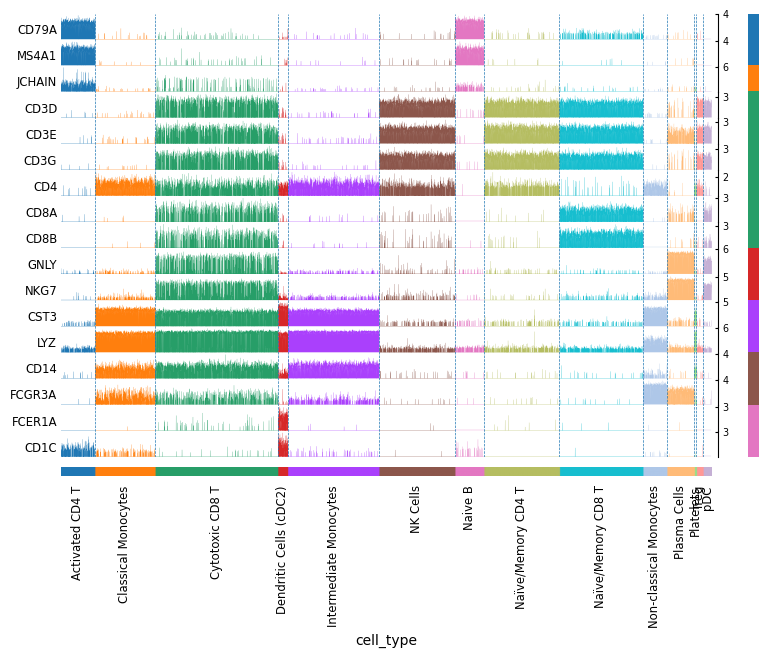

In [95]:
# Tracksplot
sc.pl.tracksplot(
    scrna, marker_genes, groupby="cell_type", dendrogram=False, 
    figsize=[9, 6]
)

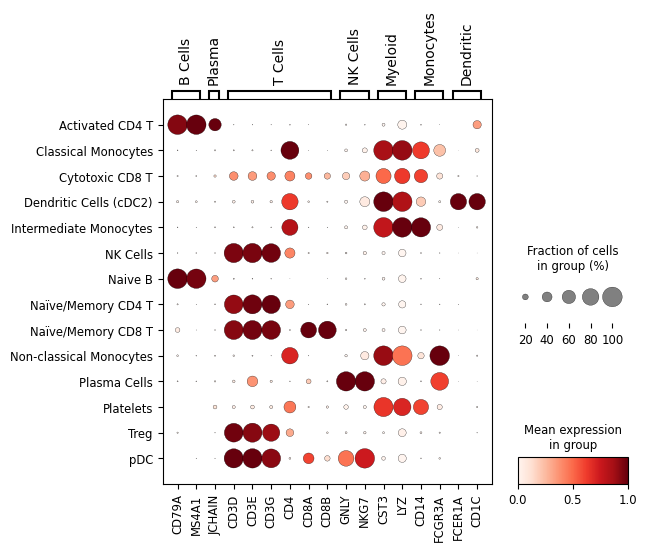

In [83]:
sc.pl.dotplot(
    scrna, marker_genes, groupby="cell_type", standard_scale="var",
    figsize=[6, 5]
)